# From model weights to an LLM reviewer
## What we export, what the reviewer sees, and what it must predict

This notebook illustrates the **ablation-prediction study**. Its central question is whether an LLM can use a small model's weights—and, in two conditions, input/output probes—to predict what will happen when individual neurons are disabled.

All exports here use the handcrafted calibration model and temporary demonstration sessions. No LLM is called, no reviewer response is fabricated, and no real session is created.

In [1]:
from pathlib import Path
import json, sys, tempfile
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

ROOT = Path.cwd().resolve()
if not (ROOT / 'experiment.json').exists():
    ROOT = ROOT.parent
if not (ROOT / 'experiment.json').exists():
    raise FileNotFoundError('Open the notebook from the project root or notebooks/ directory.')
sys.path.insert(0, str(ROOT / 'src'))
from weight_reader.evidence import export_review
from weight_reader.probe import probe_round
from weight_reader.model import WeightReaderMLP

config = json.loads((ROOT / 'experiment.json').read_text())
checkpoint = ROOT / 'checkpoints' / 'calibration.pt'
template = ROOT / 'prompts' / 'REVIEWER_PROMPT.md'
OUT = ROOT / 'results' / 'figures'
OUT.mkdir(parents=True, exist_ok=True)
torch.set_num_threads(1)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 300, 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold', 'figure.facecolor': 'white'})
def export_figure(fig, name):
    fig.savefig(OUT / f'{name}.png', bbox_inches='tight', facecolor='white')
    fig.savefig(OUT / f'{name}.svg', bbox_inches='tight', facecolor='white')

# Synthetic examples are isolated from the repository's actual reviewer sessions.
temporary = tempfile.TemporaryDirectory(prefix='weight-reader-export-demo-')
demo_root = Path(temporary.name)
conditions = ('weights_only', 'fixed_probes', 'adaptive_probes')
exports = {}
for condition in conditions:
    packet_path, prompt_path = export_review(demo_root, f'demo-{condition}', checkpoint,
        condition, 'illustrative-reviewer', 'calibration', config, template)
    exports[condition] = {'packet_path': packet_path, 'prompt_path': prompt_path,
                          'packet': json.loads(packet_path.read_text()),
                          'prompt': prompt_path.read_text()}
print('Created three temporary calibration exports. No LLM calls were made.')

Created three temporary calibration exports. No LLM calls were made.


## 1. Why export?

The exporter turns a checkpoint into a **reviewer-facing weight packet** and a **rendered prompt**. It also creates a private record tying an opaque packet ID to the selected checkpoint, condition, and reviewer. For probe conditions, it snapshots the same checkpoint for the probe relay.

The operator starts a fresh conversation and sends the rendered prompt, which already contains the full packet. The operator relays input/logit pairs only when the selected condition permits them. No project files, target labels, hidden evaluation samples, or ablation outcomes are supplied.

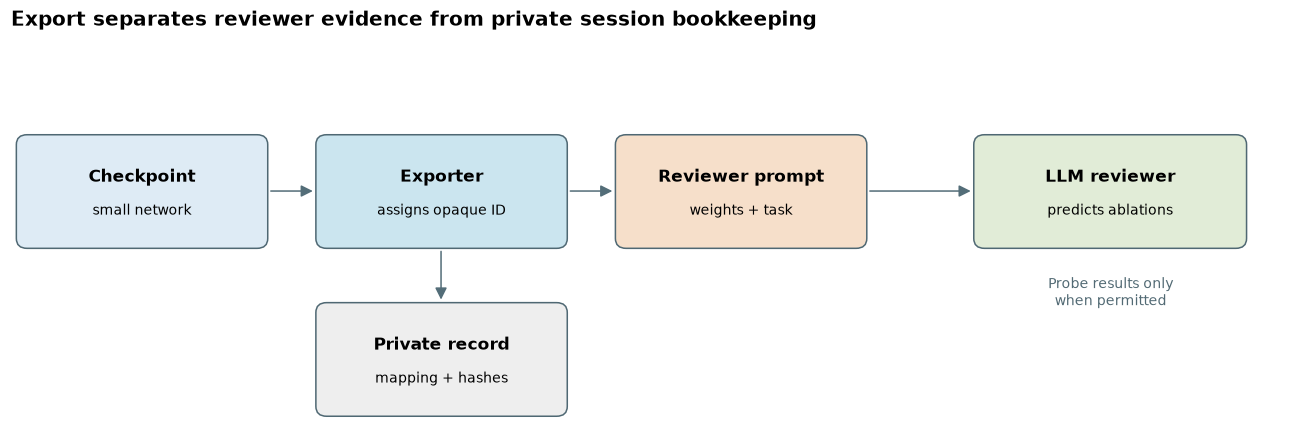

In [2]:
fig, ax = plt.subplots(figsize=(12, 4.2))
ax.set(xlim=(0,12), ylim=(0,4)); ax.axis('off')
boxes = [(0.15,2.0,2.15,.95,'Checkpoint','small network','#deebf5'),
         (2.95,2.0,2.15,.95,'Exporter','assigns opaque ID','#cbe5ef'),
         (5.75,2.0,2.15,.95,'Reviewer prompt','weights + task','#f6dfca'),
         (9.1,2.0,2.35,.95,'LLM reviewer','predicts ablations','#e1ecd7'),
         (2.95,.3,2.15,.95,'Private record','mapping + hashes','#eeeeee')]
for x,y,w,h,title,subtitle,color in boxes:
    ax.add_patch(FancyBboxPatch((x,y),w,h,boxstyle='round,pad=.1',facecolor=color,edgecolor='#4f6873'))
    ax.text(x+w/2,y+.62,title,ha='center',va='center',weight='bold',fontsize=11)
    ax.text(x+w/2,y+.28,subtitle,ha='center',va='center',fontsize=9)
for x0,y0,x1,y1 in [(2.4,2.48,2.85,2.48),(5.2,2.48,5.65,2.48),(8,2.48,9,2.48),(4.02,1.9,4.02,1.35)]:
    ax.add_patch(FancyArrowPatch((x0,y0),(x1,y1),arrowstyle='-|>',mutation_scale=16,color='#536d78'))
ax.text(10.28,1.45,'Probe results only\nwhen permitted',ha='center',va='center',fontsize=9,color='#526a74')
ax.set_title('Export separates reviewer evidence from private session bookkeeping',loc='left',pad=10)
fig.tight_layout(); export_figure(fig, '08_export_workflow'); plt.show()

## 2. What is in the weight packet?

Each packet contains the network architecture, activation type, output convention, and all six parameter tensors. The first dimension of each weight tensor is the output dimension. Values are exported as JSON numbers with enough precision to reconstruct the stored float32 weights.

The packet ID is a random identifier. It links a submitted response to the packet without revealing the source checkpoint or reviewer identity. This example shows dimensions rather than presenting the calibration weights as a result.

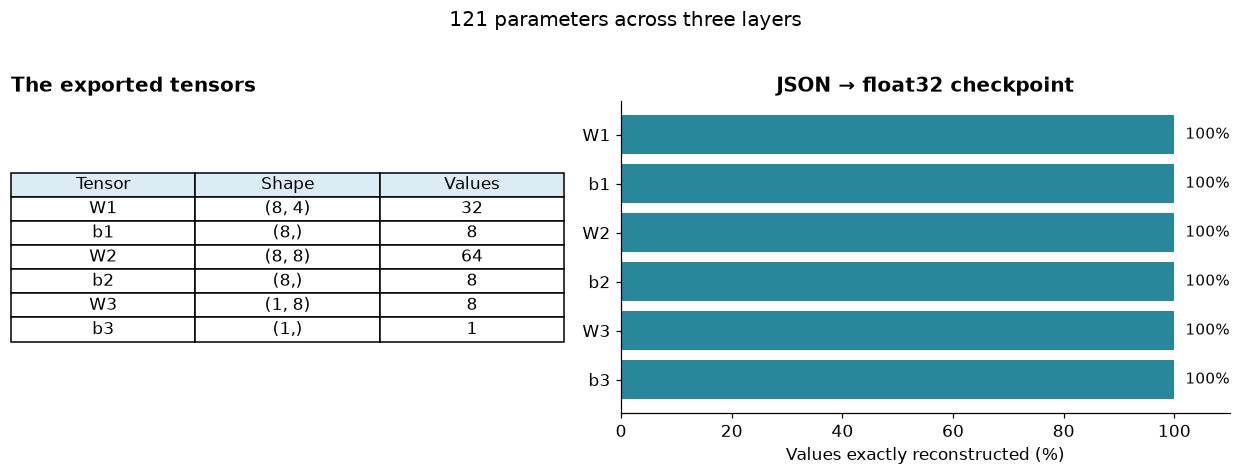

Packet fields: packet_id, architecture, hidden_activation, output, weight_orientation, parameters
All exported parameters match the calibration checkpoint exactly: True


In [3]:
packet = exports['weights_only']['packet']
params = packet['parameters']
rows=[]
for label in ('W1','b1','W2','b2','W3','b3'):
    arr = np.asarray(params[label],dtype=np.float32)
    rows.append({'tensor':label, 'shape':str(arr.shape), 'values':arr.size})
df = pd.DataFrame(rows)
fig, axes = plt.subplots(1,2,figsize=(11.5,4.2),gridspec_kw={'width_ratios':[1.0,1.1]})
ax=axes[0]; ax.axis('off'); ax.set_title('The exported tensors',loc='left')
table=ax.table(cellText=df.values,colLabels=['Tensor','Shape','Values'],cellLoc='center',loc='center',colColours=['#dcecf4']*3)
table.auto_set_font_size(False); table.set_fontsize(11); table.scale(1,1.5)
ax=axes[1]
state = torch.load(checkpoint,map_location='cpu',weights_only=True)
restored = WeightReaderMLP()
keys = {'W1':'fc1.weight','b1':'fc1.bias','W2':'fc2.weight','b2':'fc2.bias','W3':'fc3.weight','b3':'fc3.bias'}
restored.load_state_dict({key:torch.tensor(params[name],dtype=state[key].dtype) for name,key in keys.items()})
exact = [torch.equal(restored.state_dict()[key],state[key]) for key in keys.values()]
ax.barh(df['tensor'], [100*ok for ok in exact], color='#28879a'); ax.invert_yaxis(); ax.set_xlim(0,110)
ax.set(xlabel='Values exactly reconstructed (%)',title='JSON → float32 checkpoint')
for i in range(len(exact)): ax.text(102,i,'100%',va='center',fontsize=10)
fig.suptitle(f"{sum(r['values'] for r in rows)} parameters across three layers",y=1.02,fontsize=13)
fig.tight_layout(); export_figure(fig, '09_exported_weights'); plt.show()
print('Packet fields:', ', '.join(packet.keys()))
print('All exported parameters match the calibration checkpoint exactly:', all(exact))

## 3. Three evidence conditions

All conditions start with the same weights and the same final prediction task. They differ only in the additional forward-pass evidence:

- **Weights only:** the LLM predicts immediately.
- **Fixed probes:** the operator provides four predefined batches of eight input/logit pairs.
- **Adaptive probes:** the LLM chooses four batches of eight inputs, using earlier logits to choose later batches.

Both probe conditions allow 32 inputs. Repeated inputs count. Probes return ordinary logits from the frozen model—not labels, hidden activations, or ablation results.

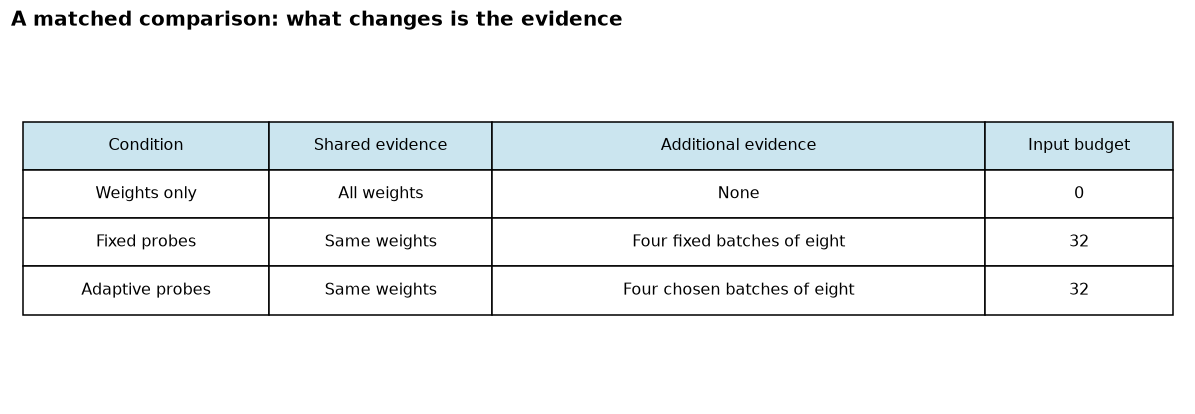

weights_only: condition instructions and packet rendered: True
fixed_probes: condition instructions and packet rendered: True
adaptive_probes: condition instructions and packet rendered: True


In [4]:
fig, ax = plt.subplots(figsize=(11,3.9)); ax.axis('off')
data=[['Weights only','All weights','None','0'],
      ['Fixed probes','Same weights','Four fixed batches of eight','32'],
      ['Adaptive probes','Same weights','Four chosen batches of eight','32']]
table=ax.table(cellText=data,colLabels=['Condition','Shared evidence','Additional evidence','Input budget'],
               cellLoc='center',loc='center',colColours=['#cbe5ef']*4,colWidths=[.21,.19,.42,.16])
table.auto_set_font_size(False); table.set_fontsize(10.5); table.scale(1,2.35)
ax.set_title('A matched comparison: what changes is the evidence',loc='left',pad=5)
fig.tight_layout(); export_figure(fig, '10_evidence_conditions'); plt.show()
for condition in conditions:
    prompt = exports[condition]['prompt']
    print(condition + ':', 'condition instructions and packet rendered:', '{{' not in prompt)

### Example of what a fixed-probe reviewer receives

The sample below comes from the temporary calibration session. Only the printed input/logit pair is relayed. The session ID and checkpoint mapping remain private. This is an example of the interface, not an LLM response.

In [5]:
fixed = probe_round(demo_root, 'demo-fixed_probes', 1)
example = {'input': fixed['inputs'][0], 'logit': fixed['logits'][0]}
print(json.dumps(example, indent=2))
print('\nThe actual round contains',len(fixed['inputs']),'input/logit pairs.')

{
  "input": [
    0.24093711376190186,
    0.3438633680343628,
    0.19821393489837646,
    -0.5518385171890259
  ],
  "logit": 2.4093711376190186
}

The actual round contains 8 input/logit pairs.


## 4. What is the LLM expected to predict?

The prompt asks the reviewer to describe all eight first-layer neurons and provide testable numerical predictions—not just plausible prose. For each neuron, it predicts activation probability and the mean effect of zeroing that neuron in each of four x₀/x₁ quadrants.

**Ablation effect = logit after disabling the neuron − original logit.** A positive value predicts that disabling the neuron raises the logit; a negative value predicts that it lowers the logit. The reviewer also ranks neuron importance and selects a pair whose *simultaneous* ablation effect it predicts. The measured pair effect need not equal the sum of individual effects.

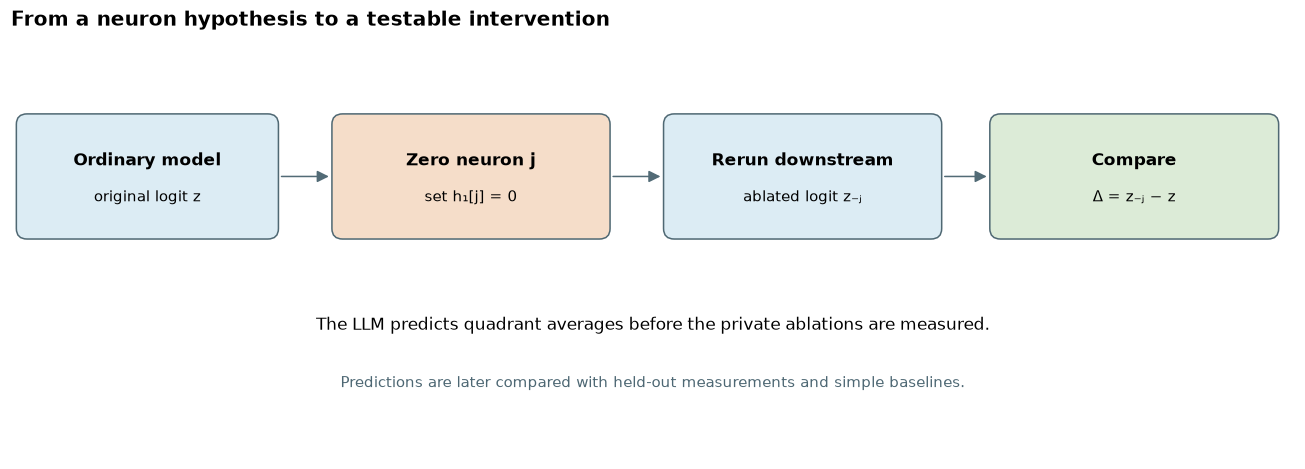

In [6]:
fig, ax = plt.subplots(figsize=(12,4.4)); ax.set(xlim=(0,12),ylim=(0,4)); ax.axis('off')
blocks=[(.15,2.2,2.25,1.0,'Ordinary model','original logit z','#dcecf4'),
        (3.1,2.2,2.4,1.0,'Zero neuron j','set h₁[j] = 0','#f5ddc9'),
        (6.2,2.2,2.4,1.0,'Rerun downstream','ablated logit z₋ⱼ','#dcecf4'),
        (9.25,2.2,2.5,1.0,'Compare','Δ = z₋ⱼ − z','#dcebd7')]
for x,y,w,h,title,sub,color in blocks:
    ax.add_patch(FancyBboxPatch((x,y),w,h,boxstyle='round,pad=.10',facecolor=color,edgecolor='#4f6873'))
    ax.text(x+w/2,y+.65,title,ha='center',va='center',weight='bold')
    ax.text(x+w/2,y+.30,sub,ha='center',va='center',fontsize=10)
for x0,x1 in [(2.5,3),(5.6,6.1),(8.7,9.15)]:
    ax.add_patch(FancyArrowPatch((x0,2.7),(x1,2.7),arrowstyle='-|>',mutation_scale=16,color='#526b76'))
ax.text(6,1.23,'The LLM predicts quadrant averages before the private ablations are measured.',ha='center',fontsize=11)
ax.text(6,.68,'Predictions are later compared with held-out measurements and simple baselines.',ha='center',fontsize=10,color='#4d6773')
ax.set_title('From a neuron hypothesis to a testable intervention',loc='left',pad=10)
fig.tight_layout(); export_figure(fig, '11_ablation_prediction'); plt.show()

### Required final response

The final submission is one JSON object containing:

- The packet ID and a brief hypothesis about the overall function.
- Exactly eight neuron entries, each with an activation description, downstream-role hypothesis, four activation probabilities, four signed ablation-effect predictions, and uncertainty.
- A complete importance ranking of the eight neuron IDs.
- One pair of distinct neurons, a group hypothesis, and four predicted simultaneous-ablation effects.

Quadrants are ordered **Q++**, **Q+-**, **Q-+**, **Q--**, where Q++ means x₀ > 0 and x₁ > 0. The LLM is not given the target rule in this original ablation task; it is asked to infer the model's behavior from its permitted evidence.

## 5. After export

1. Start a fresh conversation for each reviewer, condition, and checkpoint. Send its rendered prompt; deliver fixed or adaptive probe feedback as required.
2. Preserve the reviewer's final response and freeze predictions before measuring held-out neuron ablations.
3. Compare numerical predictions with measured effects and baselines. Record missing or malformed responses, and distinguish calibration from trained-model results.

The exporter and manual probe relay are implemented. **Reviewer response import, protocol freeze, ablation scoring, and report generation are not yet implemented.** This prompt asks for ablation predictions, not a proposed weight repair. A separate editing protocol is still needed. Paid collection requires explicit authorization.